# Coma ACS Catalogue Check

## Purpose

While going through detection and photometry in the HST/ACS catalog, I discuvered some astrometry discrepancies which need to be qualified. This notebook serves that purpose. 

## Outline

- load database
- load fits for each HST image to obtain WCS
- first check the pixel-to-world conversion for each object and establish scatter;


# Configuration

Setup project directories and logging

In [1]:
# Project initialization
from pathlib import Path
import sys
import os
import json
import logging
from datetime import datetime, timezone

# Module imports
import numpy as np
import pandas as pd
import pickle

import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Tuple, Optional, Dict
from tqdm.auto import tqdm

import ast
import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from astropy.stats import rayleightest
from scipy.stats import binomtest, ks_2samp, chi2, spearmanr

from shapely.geometry import Polygon, Point

%load_ext autoreload
%autoreload 2


def find_project_root(marker="src/acs_astrometry.py"):
    path = Path.cwd().resolve()

    for candidate in [path, *path.parents]:
        if (candidate / marker).is_file():
            return candidate

    raise RuntimeError("Could not locate project root")

PROJECT_ROOT = find_project_root()

HOME_DIR = Path(
    os.environ.get("COMA_WORKSPACE_DIR", PROJECT_ROOT.parent)
).expanduser().resolve()

PROJECT_PATH = PROJECT_ROOT

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
FIGURE_DIR = PROJECT_ROOT / "figures"

ACS_PROJECT_DIR = Path(
    os.environ.get(
        "COMA_ACS_PROJECT_DIR",
        HOME_DIR / "Coma_Intracluster_GC"
    )
).expanduser().resolve()

# set path to ACS fits and data subdirectories
REGIONS_DIR = ACS_PROJECT_DIR / "regions"
ACS_DATA_DIR = ACS_PROJECT_DIR / "data"





from src.io_utils import setup_logging

# Set verbosity here:
setup_logging(verbose=True, name='ACS_astrometry_check')   # or False

# testing logging
logger = logging.getLogger("ACS_astrometry_check")
logger.debug("Debug messages are ON")
logger.info("Info messages are always shown")
logger.warning("Warnings also show up")

logger.info("Project root: %s", PROJECT_ROOT)

[DEBUG] 19:54:48.651 Debug messages are ON
Info messages are always shown
[WARNING] 19:54:48.652 Warnings also show up
Project root: /Users/richard/PycharmProjects/coma-acs-astrometry


## Load CSS candidates

Now we have galaxy data, we need to load up the CSS candidate file. 

In [2]:
#inFileName = "allpointings_master.dat_NoOverlap"
# inFileName = "data/newallpointingsmaster_26may2021.dat"  # with delimeter ' '
inFileName = ACS_DATA_DIR / "inspectedpointings_merged_19Oct2024.csv"  # with delimieter ','

inFile = open(inFileName, 'r')
lines = inFile.readlines()
inFile.close

data = pd.read_csv(inFileName, delimiter=',')


and then we need to filter for color on CSS in general, and additional filter for UCDs on the tighter color range and luminosity, and outlined in paper 1. Color value are 

- CSS: *color* 0.5 < (F475W − F814W ) < 2.5 and 
- UCD: *color* 1.3 < (F475W − F814W ) < 2.1 and *magnitude* F814W < 22.9 mag


In [3]:
# data = data[(data['color'] > 0.5) & (data['color'] < 2.5)]
# data_bright = data.loc[data['mag_814']<=25.0].copy()  # take a cut of data where completeness is > ~90% 

# Define the range for UCD 'color' and 'mag_814'
ucd_color_min, ucd_color_max = 1.3, 2.1     #
ucd_mag_814_min, ucd_mag_814_max = 0, 22.9  # should be 0 mag to 22.9 mag

# remove duplicated data
data = data.drop_duplicates()

# Filter the DataFrame
gcs_df = data[(data['color'] <= ucd_color_min) | (data['color'] >= ucd_color_max) |
                 (data['mag_814'] <= ucd_mag_814_min) | (data['mag_814'] >= ucd_mag_814_max)]
ucd_df = data[(data['color'] > ucd_color_min) & (data['color'] < ucd_color_max) &
                 (data['mag_814'] > ucd_mag_814_min) & (data['mag_814'] < ucd_mag_814_max)]


In [4]:
total_gcs = len(gcs_df)
total_ucds = len(ucd_df)
total_css = len(data)
# total_bright = len(data_bright)

print('Total GCs: ', total_gcs)
print('Total UCDs: ', total_ucds)
print('Total count: ', total_css)
# print('Total bright (F814W ≤ 25.0 mag): ', total_bright)
print('Mag F814W min, max:', np.min(data['mag_814']), np.max(data['mag_814']) )
print('Mag F475W min, max:', np.min(data['mag_475']), np.max(data['mag_475']) )

logger.warning("ACS DATA loaded - NOTE: NON-CSS Candidates included in data.")
data.head(5)


[WARNING] 19:55:32.882 ACS DATA loaded - NOTE: NON-CSS Candidates included in data.


Total GCs:  22828
Total UCDs:  523
Total count:  23351
Mag F814W min, max: 16.66917944 31.40208019
Mag F475W min, max: 18.59635274 35.85504431


,x_wcs,y_wcs,flux_814,flux_475,mag_814,mag_475,color,pointing,x,y,type,x_wcs_f,y_wcs_f,gc_type_f,pointing_f,Unnamed: 15
0,194.09794,27.244074,0.458373,0.203884,26.152547,27.681062,1.528516,OS21,708.977,3994.384,gc,194.09794,27.244074,gc,OS21,NaN
1,194.09828,27.212645,1.207550,1.165456,25.100832,25.788280,0.687449,OS21,2964.827,4170.375,gc,194.09828,27.212645,gc,OS21,NaN
2,194.09871,27.212720,1.866294,0.250135,24.628144,27.459086,2.830941,OS21,2962.660,4141.720,gc,194.09871,27.212720,gc,OS21,NaN
3,194.09916,27.222516,4.788598,2.630347,23.605074,24.904488,1.299414,OS21,2261.617,4052.017,gc,194.09916,27.222516,gc,OS21,NaN
4,194.09917,27.213105,4.268017,1.134324,23.730029,25.817677,2.087648,OS21,2937.748,4109.924,gc,194.09917,27.213105,gc,OS21,NaN


In [5]:

def check_acs_wcs(catalogue, images, pixel_origin=0):

    results = []

    for pointing, path in images.items():

        subset = catalogue[
            catalogue["pointing"] == pointing
        ].copy()

        if subset.empty:
            continue

        with fits.open(path) as hdul:
            wcs = WCS(
                hdul["SCI", 1].header, hdul
            ).celestial

        # Convert catalogue pixels to Astropy's
        # zero-based pixel-coordinate convention.
        x = subset["x"].to_numpy(float) - pixel_origin
        y = subset["y"].to_numpy(float) - pixel_origin

        # Coordinates predicted by the FITS image WCS
        calculated = wcs.pixel_to_world(x, y)

        # Original catalogue coordinates
        original = SkyCoord(
            ra=subset["x_wcs"].to_numpy(float) * u.deg,
            dec=subset["y_wcs"].to_numpy(float) * u.deg,
            frame="icrs"
        )

        # Tangent-plane differences: calculated - catalogue
        dra, ddec = original.spherical_offsets_to(calculated)

        subset["wcs_dra_arcsec"] = dra.arcsec
        subset["wcs_ddec_arcsec"] = ddec.arcsec

        subset["wcs_sep_arcsec"] = (
            original.separation(calculated).arcsec
        )

        results.append(subset)

    return pd.concat(results, ignore_index=True)


In [6]:
acs_catalogue = data.copy()

ACS_IMAGES = {
    "2-0": REGIONS_DIR / "2-0/jc1g01010_drc.fits",
    "3-0": REGIONS_DIR / "3-0/jc1g02010_drc.fits",
}

for origin in (0, 1):

    checked = check_acs_wcs(
        acs_catalogue,
        ACS_IMAGES,
        pixel_origin=origin
    )

    print(f"\nPixel origin: {origin}")

    summary = checked.groupby("pointing").agg(
        n=("wcs_sep_arcsec", "size"),
        median_dra=("wcs_dra_arcsec", "median"),
        median_ddec=("wcs_ddec_arcsec", "median"),
        median_sep=("wcs_sep_arcsec", "median"),
        p95_sep=("wcs_sep_arcsec",
                 lambda s: np.nanpercentile(s, 95)),
        max_sep=("wcs_sep_arcsec", "max"),
    )

    display(summary.round(5))



Pixel origin: 0


,n,median_dra,median_ddec,median_sep,p95_sep,max_sep
pointing,,,,,,
2-0,1422,-0.31394,0.40222,0.50992,0.52128,1.90044
3-0,625,-0.02134,0.32610,0.32711,0.33997,0.34685



Pixel origin: 1


,n,median_dra,median_ddec,median_sep,p95_sep,max_sep
pointing,,,,,,
2-0,1422,-0.24669,0.42407,0.49007,0.49992,1.89550
3-0,625,0.04120,0.35910,0.36145,0.37505,0.38183


1. Using the zero-based pixel convention, this shows:

| Pointing | Objects | ΔRA cos(Dec) | ΔDec | Median separation |
| --- | --- | --- | --- | --- |
| 2-0 | 1,422 | −0.314″ | +0.402″ | 0.510″ |
| 3-0 | 625 | −0.021″ | +0.326″ | 0.327″ |

These are the coordinates calculated from the current ACS F814W image WCS minus the stored catalogue coordinates.

Both fields show substantial discrepancies, but in different directions. Crucially, changing from zero-based to one-based pixel coordinates doesn't eliminate them. A one-pixel origin adjustment is far too small to account for these offsets. 

So we can say with considerable confidence:

> The catalogue's stored pixel positions and sky coordinates are not mutually consistent under the WCS solutions in our current F814W drizzle products.

That doesn't yet establish which representation is correct, but it's an important discovery.

2. The apparent consistency within each field is particularly revealing
Look at the median and 95th-percentile separations:
| Pointing | Median | 95th percentile | Maximum |
| --- | --- | --- | --- |
| 2-0 | 0.510″ | 0.521″ | 1.900″ |
| 3-0 | 0.327″ | 0.340″ | 0.347″ |

In both cases, the 95th-percentile separation is only about 0.01″ larger than the median. That's suggestive of a nearly constant positional translation across each field, rather than large, irregular WCS distortions. There is one exception: the 1.900″ maximum in field 2-0. That's clearly worth isolating and inspecting. However, we should check the scatter in the individual RA and Dec components before concluding that the discrepancies are rigid translations. A nearly constant separation magnitude doesn't necessarily mean the offset direction is constant.

3. Our next diagnostic should be the scatter after subtracting the median translatio.

This is a useful test because it separates the bulk offset from any remaining spatially varying errors.

Let's use pixel_origin=0 for this initial diagnostic, without yet assuming it is the correct historical convention.

In [7]:
audit = check_acs_wcs(
    acs_catalogue,
    ACS_IMAGES,
    pixel_origin=0
)

summary = []
parts = []

for pointing, group in audit.groupby("pointing"):

    group = group.copy()

    dx = group["wcs_dra_arcsec"].to_numpy()
    dy = group["wcs_ddec_arcsec"].to_numpy()

    # Robust bulk offset
    med_dx = np.nanmedian(dx)
    med_dy = np.nanmedian(dy)

    # Residual after removing translation
    group["relative_dra"] = dx - med_dx
    group["relative_ddec"] = dy - med_dy

    group["relative_sep"] = np.hypot(
        group["relative_dra"],
        group["relative_ddec"]
    )

    r = group["relative_sep"].to_numpy()

    summary.append({
        "pointing": pointing,
        "n": len(group),
        "median_dx": med_dx,
        "median_dy": med_dy,
        "median_residual": np.nanmedian(r),
        "p95_residual": np.nanpercentile(r, 95),
        "max_residual": np.nanmax(r)
    })

    parts.append(group)

audit_relative = pd.concat(parts, ignore_index=True)

display(pd.DataFrame(summary).round(5))


,pointing,n,median_dx,median_dy,median_residual,p95_residual,max_residual
0,2-0,1422,-0.31394,0.40222,0.00906,0.01864,1.41347
1,3-0,625,-0.02134,0.32610,0.00931,0.02132,0.20428


This provides evidence that the discrepancy is dominated by a pointing-dependent translation, rather than a complicated distortion problem.

For both pointings, the median remaining discrepancy is approximately 9 milliarcseconds, and 95% of objects fall within roughly 20 milliarcseconds of the median translation.

At our JWST image scale, that's a median of about 0.29 pixels.

and the outliers...

In [8]:
outliers = (
    audit_relative[
        audit_relative["relative_sep"] > 0.05
    ]
    .sort_values("relative_sep", ascending=False)
)

print("Objects with residual > 0.05 arcsec:")
print(outliers.groupby("pointing").size())

display(
    outliers[
        ["pointing", "x", "y",
         "x_wcs", "y_wcs",
         "relative_dra", "relative_ddec",
         "relative_sep"]
    ].round(6)
)


Objects with residual > 0.05 arcsec:
pointing
2-0    8
3-0    1
dtype: int64


,pointing,x,y,x_wcs,y_wcs,relative_dra,relative_ddec,relative_sep
526,2-0,4023.608,2526.765,195.22693,28.006793,-0.430773,1.346233,1.413474
506,2-0,3955.258,2564.650,195.22657,28.008599,0.577025,-1.250387,1.377108
476,2-0,3994.107,2580.683,195.22606,28.008181,0.601919,-1.112444,1.264847
577,2-0,3995.237,2502.300,195.22773,28.007409,-1.239579,-0.162711,1.250212
584,2-0,3944.140,2514.001,195.22785,28.008262,-0.982462,-0.691497,1.201416
615,2-0,4005.345,2443.044,195.22837,28.006802,-0.863280,0.227160,0.892667
438,2-0,4036.683,2621.664,195.22531,28.007547,0.193576,0.203305,0.280722
1694,3-0,224.417,3367.734,195.22113,28.005536,-0.001017,-0.204281,0.204284
1039,2-0,4139.193,1653.880,195.23816,28.000250,0.137991,-0.062746,0.151587


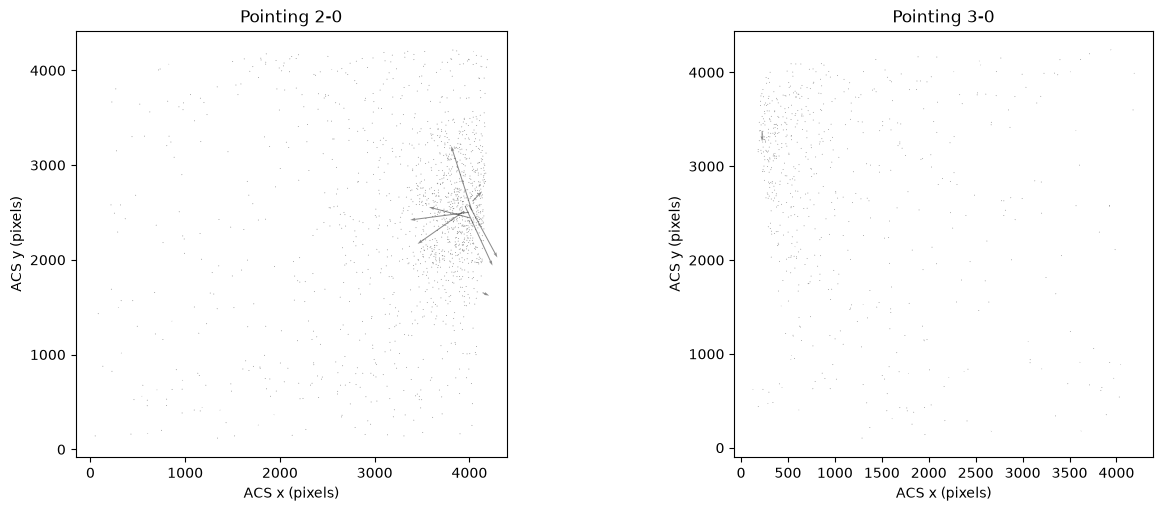

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5),
    constrained_layout=True
)

for ax, (pointing, group) in zip(
    axes, audit_relative.groupby("pointing")
):
    ax.quiver(
        group["x"],
        group["y"],
        group["relative_dra"],
        group["relative_ddec"],
        angles="xy",
        scale_units="xy",
        scale=0.002,
        alpha=0.45
    )

    ax.set_title(f"Pointing {pointing}")
    ax.set_xlabel("ACS x (pixels)")
    ax.set_ylabel("ACS y (pixels)")
    ax.set_aspect("equal")

plt.show()


## Inspect Outlier objects


In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.nddata import Cutout2D

ACS_IMAGES = {
    "2-0": REGIONS_DIR / "2-0/jc1g01010_drc.fits",
    "3-0": REGIONS_DIR / "3-0/jc1g02010_drc.fits",
}
fits_files = ACS_IMAGES

df = outliers.copy()

RA_COL = "x_wcs"
DEC_COL = "y_wcs"
X_COL = "x"
Y_COL = "y"

SCI_EXT = "SCI"   # Change to 1 or another extension if needed
PIXEL_ORIGIN = 0  # Astropy/NumPy convention
CUTOUT_SIZE = 81  # Pixels

In [11]:
def inspect_fits_wcs(filepath, ext="SCI"):
    with fits.open(filepath) as hdul:
        hdul.info()

        hdu = hdul[ext]
        header = hdu.header
        wcs = WCS(header, hdul).celestial

        print(f"\nFile: {filepath}")
        print(f"Shape: {hdu.data.shape}")
        print(f"CTYPE: {wcs.wcs.ctype}")
        print(f"CRPIX: {wcs.wcs.crpix}")
        print(f"CRVAL: {wcs.wcs.crval}")
        print(f"CUNIT: {wcs.wcs.cunit}")

        print("\nPixel scale matrix:")
        print(wcs.pixel_scale_matrix)

        return wcs

for pointing, path in fits_files.items():
    print(f"\n{'=' * 50}")
    print(f"POINTING {pointing}")
    inspect_fits_wcs(path, SCI_EXT)



POINTING 2-0
Filename: /Users/richard/PycharmProjects/Coma_Intracluster_GC/regions/2-0/jc1g01010_drc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     883   ()      
  1  SCI           1 ImageHDU        87   (4227, 4298)   float32   
  2  WHT           1 ImageHDU        44   (4227, 4298)   float32   
  3  CTX           1 ImageHDU        37   (4227, 4298)   int32   
  4  HDRTAB        1 BinTableHDU    595   8R x 293C   [9A, 3A, K, D, D, D, D, D, D, D, D, D, D, D, D, D, K, 8A, 9A, 7A, 18A, 4A, D, D, D, D, 3A, D, D, D, D, D, D, D, D, D, D, D, D, K, 8A, 23A, D, D, D, D, K, K, K, 8A, K, 23A, 9A, 20A, K, 4A, K, D, K, K, K, K, 23A, D, D, D, D, K, K, 3A, 3A, 4A, 4A, L, D, D, D, 3A, 1A, K, D, D, D, 24A, 3A, 4A, 4A, 12A, 12A, 23A, 8A, 23A, 10A, 10A, D, D, 3A, 3A, 23A, 4A, 8A, 7A, 23A, D, K, D, 11A, 9A, 8A, D, D, L, 4A, 18A, 3A, K, 7A, 5A, 3A, D, 13A, 8A, 4A, 3A, L, K, L, K, L, K, K, D, D, D, D, D, D, 3A, 1A, D, 23A, D, D, D, 3A, 23A, L, 1A, 3

In [12]:
def inspect_astrometric_outlier(
    row,
    fits_files,
    sci_ext="SCI",
    size=81,
    pixel_origin=0,
):
    pointing = str(row["pointing"])
    filepath = fits_files[pointing]

    # Stored catalogue coordinates
    x = float(row[X_COL]) - pixel_origin
    y = float(row[Y_COL]) - pixel_origin

    ra = float(row[RA_COL])
    dec = float(row[DEC_COL])

    with fits.open(filepath, memmap=True) as hdul:
        image = hdul[sci_ext].data
        wcs = WCS(hdul[sci_ext].header, hdul).celestial

        # Pixel -> sky using FITS WCS
        sky_from_xy = wcs.pixel_to_world(x, y)

        # Catalogue sky -> pixel using FITS WCS
        sky_catalog = SkyCoord(
            ra=ra * u.deg,
            dec=dec * u.deg,
            frame="icrs",
        )

        x_from_sky, y_from_sky = wcs.world_to_pixel(
            sky_catalog
        )

        dx = x_from_sky - x
        dy = y_from_sky - y

        separation = sky_from_xy.separation(
            sky_catalog
        ).arcsec

        print(f"\nSource: {row.name}")
        print(f"Pointing: {pointing}")
        print(f"File: {filepath.name}")
        print(f"Stored XY:       ({x:.3f}, {y:.3f})")
        print(
            f"RA/Dec -> XY:    "
            f"({x_from_sky:.3f}, {y_from_sky:.3f})"
        )
        print(f"Delta XY:        ({dx:+.3f}, {dy:+.3f}) px")
        print(f"Angular offset:  {separation:.4f} arcsec")

        # Extract two independent cutouts
        centers = [
            (x, y),
            (x_from_sky, y_from_sky),
        ]

        titles = [
            "Stored pixel position",
            "Pixel position from RA/Dec",
        ]

        fig, axes = plt.subplots(
            1, 2, figsize=(10, 5),
            constrained_layout=True
        )

        for ax, center, title in zip(
            axes, centers, titles
        ):
            cutout = Cutout2D(
                image,
                position=center,
                size=size,
                mode="partial",
                fill_value=np.nan,
                copy=True,
            )

            data = cutout.data

            finite = data[np.isfinite(data)]
            if finite.size:
                vmin, vmax = np.percentile(
                    finite, [5, 99.5]
                )
            else:
                vmin, vmax = 0, 1

            ax.imshow(
                data,
                origin="lower",
                cmap="gray",
                vmin=vmin,
                vmax=vmax,
            )

            # Mark both coordinate predictions
            for px, py, color, marker in [
                (x, y, "cyan", "+"),
                (x_from_sky, y_from_sky, "red", "x"),
            ]:
                cx, cy = cutout.to_cutout_position(
                    (px, py)
                )
                ax.plot(
                    cx, cy,
                    marker=marker,
                    color=color,
                    markersize=12,
                    markeredgewidth=2,
                    linestyle="none",
                )

            ax.set_title(title)
            ax.set_xlabel("Cutout X (pixels)")
            ax.set_ylabel("Cutout Y (pixels)")

        fig.suptitle(
            f"{pointing} | Object {row.name} | "
            f"Offset = {separation:.3f} arcsec"
        )

        plt.show()

    return {
        "pointing": pointing,
        "x": x,
        "y": y,
        "x_from_sky": x_from_sky,
        "y_from_sky": y_from_sky,
        "dx_pix": dx,
        "dy_pix": dy,
        "sep_arcsec": separation,
    }



Source: 526
Pointing: 2-0
File: jc1g01010_drc.fits
Stored XY:       (4023.608, 2526.765)
RA/Dec -> XY:    (4048.005, 2497.619)
Delta XY:        (+24.397, -29.146) px
Angular offset:  1.9004 arcsec


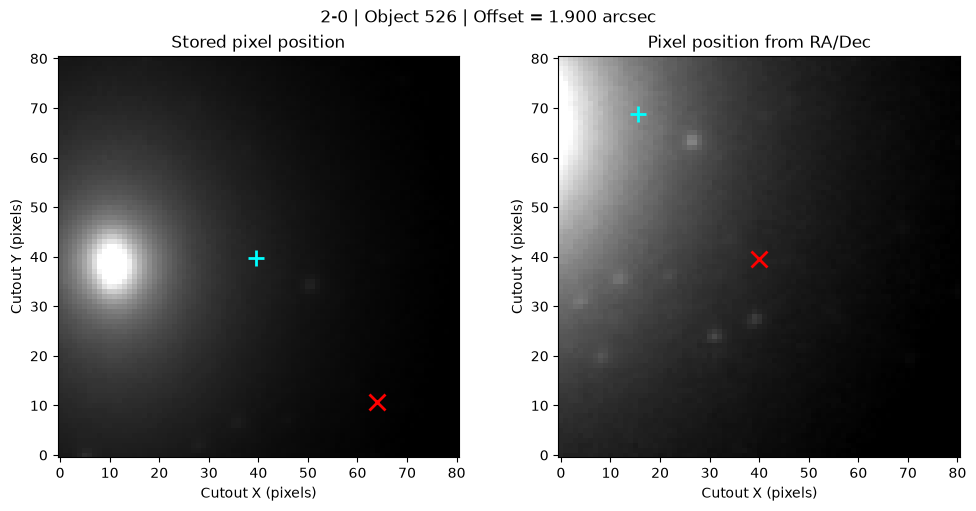


Source: 506
Pointing: 2-0
File: jc1g01010_drc.fits
Stored XY:       (3955.258, 2564.650)
RA/Dec -> XY:    (3942.532, 2577.039)
Delta XY:        (-12.726, +12.389) px
Angular offset:  0.8880 arcsec


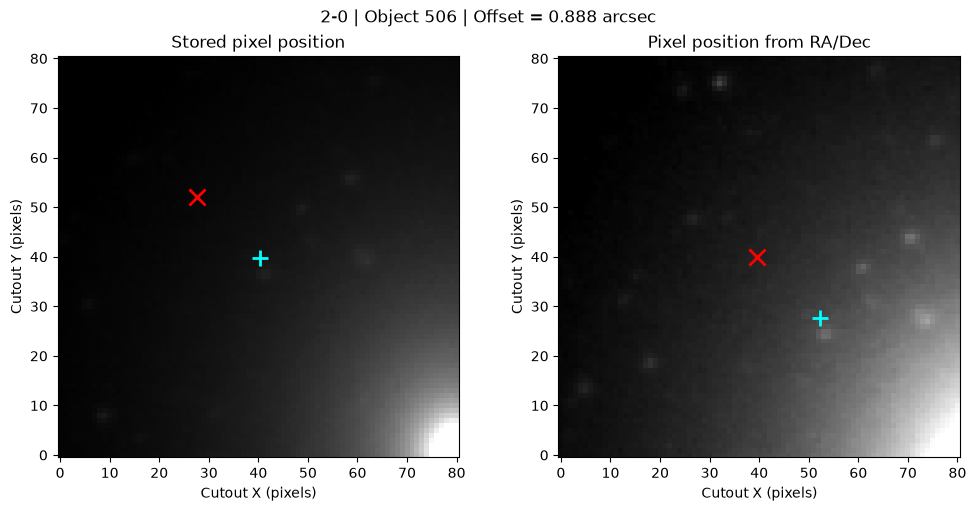


Source: 476
Pointing: 2-0
File: jc1g01010_drc.fits
Stored XY:       (3994.107, 2580.683)
RA/Dec -> XY:    (3984.065, 2592.263)
Delta XY:        (-10.042, +11.580) px
Angular offset:  0.7664 arcsec


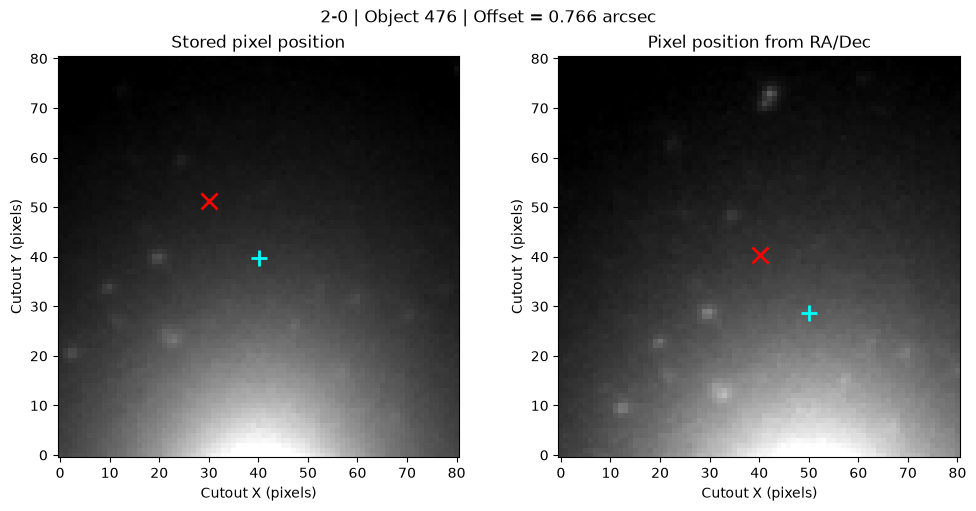


Source: 577
Pointing: 2-0
File: jc1g01010_drc.fits
Stored XY:       (3995.237, 2502.300)
RA/Dec -> XY:    (3985.400, 2472.441)
Delta XY:        (-9.837, -29.859) px
Angular offset:  1.5719 arcsec


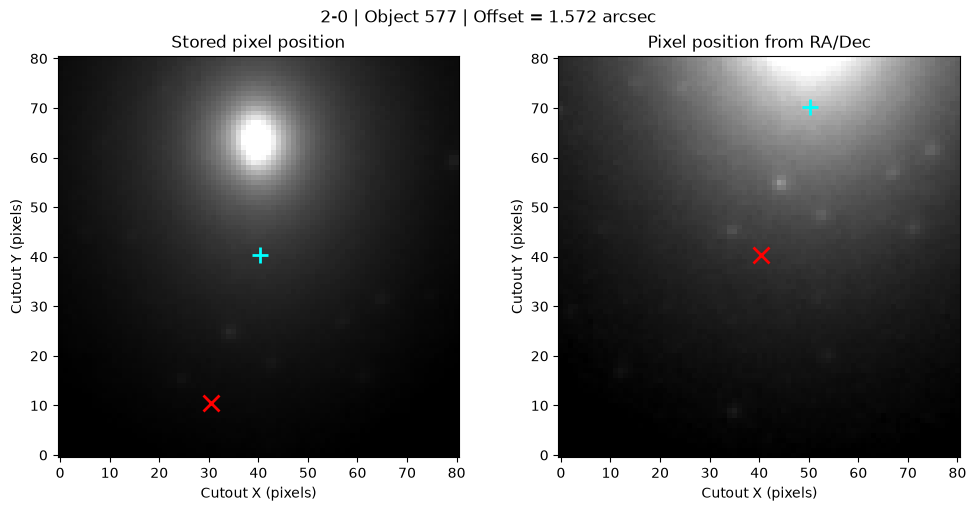


Source: 584
Pointing: 2-0
File: jc1g01010_drc.fits
Stored XY:       (3944.140, 2514.001)
RA/Dec -> XY:    (3927.214, 2493.525)
Delta XY:        (-16.926, -20.476) px
Angular offset:  1.3283 arcsec


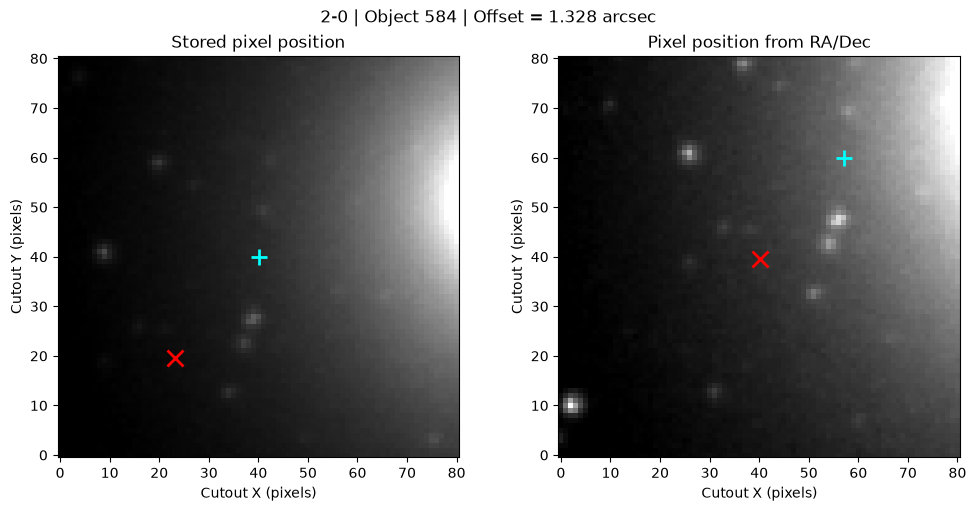


Source: 615
Pointing: 2-0
File: jc1g01010_drc.fits
Stored XY:       (4005.345, 2443.044)
RA/Dec -> XY:    (4005.872, 2416.351)
Delta XY:        (+0.527, -26.693) px
Angular offset:  1.3349 arcsec


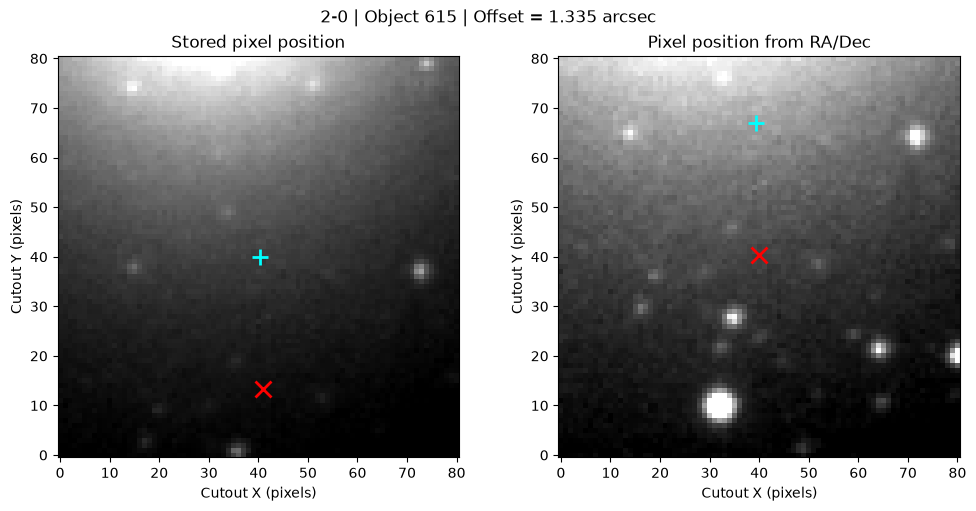


Source: 438
Pointing: 2-0
File: jc1g01010_drc.fits
Stored XY:       (4036.683, 2621.664)
RA/Dec -> XY:    (4046.381, 2614.022)
Delta XY:        (+9.698, -7.642) px
Angular offset:  0.6174 arcsec


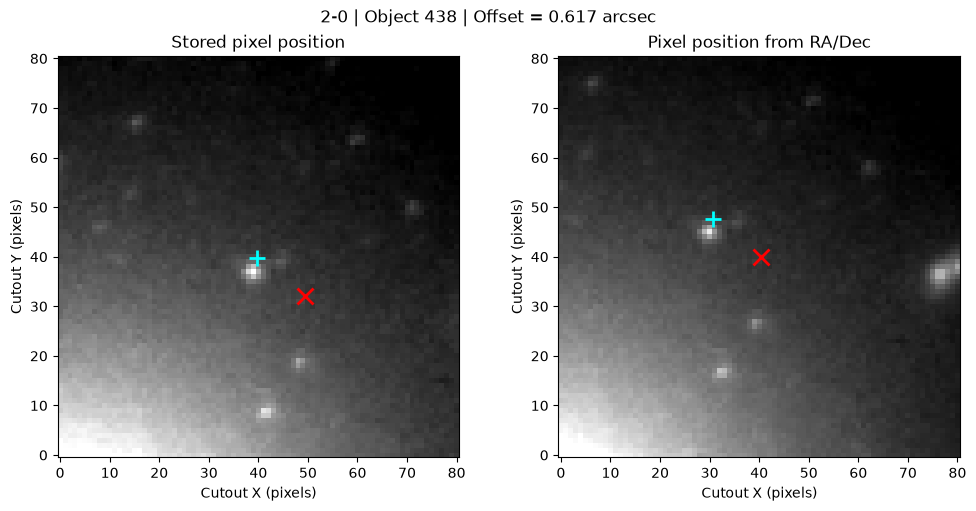


Source: 1694
Pointing: 3-0
File: jc1g02010_drc.fits
Stored XY:       (224.417, 3367.734)
RA/Dec -> XY:    (226.613, 3366.587)
Delta XY:        (+2.196, -1.147) px
Angular offset:  0.1239 arcsec


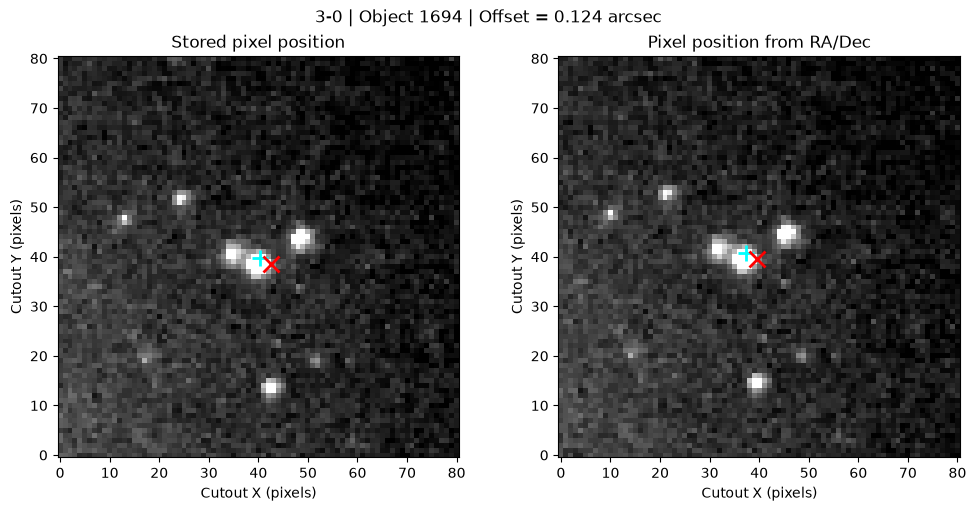


Source: 1039
Pointing: 2-0
File: jc1g01010_drc.fits
Stored XY:       (4139.193, 1653.880)
RA/Dec -> XY:    (4143.644, 1647.662)
Delta XY:        (+4.451, -6.218) px
Angular offset:  0.3824 arcsec


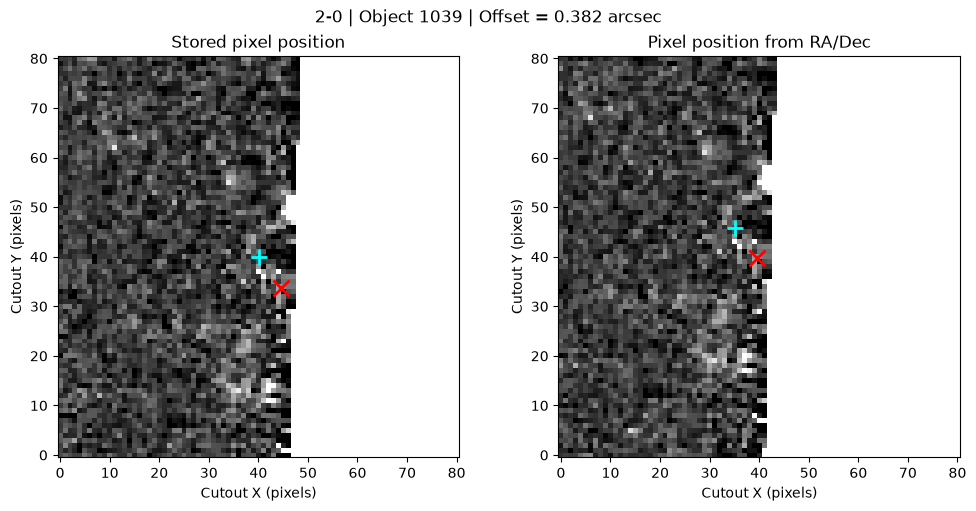

,source_id,pointing,x,y,x_from_sky,y_from_sky,dx_pix,dy_pix,sep_arcsec
0,526,2-0,4023.608,2526.765,4048.0047804714154,2497.6193866824524,24.396780,-29.145613,1.900440
1,506,2-0,3955.258,2564.650,3942.53178903162,2577.0389610335196,-12.726211,12.388961,0.888035
2,476,2-0,3994.107,2580.683,3984.0649801719446,2592.263145575309,-10.042020,11.580146,0.766391
3,577,2-0,3995.237,2502.300,3985.400215343634,2472.4411561661927,-9.836785,-29.858844,1.571872
4,584,2-0,3944.140,2514.001,3927.2144677289325,2493.5251147672934,-16.925532,-20.475885,1.328284
5,615,2-0,4005.345,2443.044,4005.872273348252,2416.351176393478,0.527273,-26.692824,1.334901
6,438,2-0,4036.683,2621.664,4046.3809873209443,2614.021558304305,9.697987,-7.642442,0.617369
7,1694,3-0,224.417,3367.734,226.61260081355795,3366.5871540387648,2.195601,-1.146846,0.123854
8,1039,2-0,4139.193,1653.880,4143.644478006121,1647.662000228263,4.451478,-6.218000,0.382358


In [13]:
results = []

for idx, row in df.iterrows():
    result = inspect_astrometric_outlier(
        row,
        fits_files,
        sci_ext=SCI_EXT,
        size=CUTOUT_SIZE,
        pixel_origin=PIXEL_ORIGIN,
    )
    results.append({"source_id": idx, **result})

import pandas as pd

diagnostics = pd.DataFrame(results)
display(diagnostics)


In [14]:
diagnostics["dr_pix"] = np.hypot(
    diagnostics["dx_pix"],
    diagnostics["dy_pix"]
)

diagnostics["r_edge_pix"] = np.nan

for pointing, group in diagnostics.groupby("pointing"):
    with fits.open(fits_files[pointing]) as hdul:
        ny, nx = hdul[SCI_EXT].data.shape

    idx = group.index
    diagnostics.loc[idx, "r_edge_pix"] = np.minimum.reduce([
        group["x"].to_numpy(),
        group["y"].to_numpy(),
        nx - 1 - group["x"].to_numpy(),
        ny - 1 - group["y"].to_numpy(),
    ])

display(
    diagnostics[
        ["source_id", "pointing", "dr_pix",
         "r_edge_pix", "sep_arcsec"]
    ].sort_values("dr_pix", ascending=False)
)

,source_id,pointing,dr_pix,r_edge_pix,sep_arcsec
0,526,2-0,38.008810,202.392,1.900440
3,577,2-0,31.437444,230.763,1.571872
5,615,2-0,26.698031,220.655,1.334901
4,584,2-0,26.565683,281.860,1.328284
1,506,2-0,17.760709,270.742,0.888035
2,476,2-0,15.327816,231.893,0.766391
6,438,2-0,12.347383,189.317,0.617369
8,1039,2-0,7.647168,86.807,0.382358
7,1694,3-0,2.477079,224.417,0.123854


In [15]:
from photutils.centroids import centroid_2dg
from astropy.nddata import Cutout2D
import numpy as np

def measure_local_centroid(image, x, y, size=15):
    cutout = Cutout2D(
        image,
        position=(x, y),
        size=size,
        mode="partial",
        fill_value=np.nan,
    )

    data = cutout.data.astype(float)
    if not np.all(np.isfinite(data)):
        return np.nan, np.nan

    # Remove approximately constant local background
    data -= np.median(data)

    xc, yc = centroid_2dg(data)

    return cutout.to_original_position((xc, yc))


In [16]:
row = df.loc[438]  # Assumes source_id is the DataFrame index

with fits.open(fits_files["2-0"]) as hdul:
    image = hdul["SCI"].data

xc, yc = measure_local_centroid(
    image,
    row["x"],
    row["y"],
)

print("Stored XY:", row["x"], row["y"])
print("Measured centroid:", xc, yc)


Stored XY: 4036.683 2621.664
Measured centroid: 4035.835624787135 2618.9037698925763


In [17]:
x_cat, y_cat = 4036.683, 2621.664
x_cent, y_cent = 4035.835624787135, 2618.9037698925763
x_sky, y_sky = 4046.3809873209443, 2614.021558304305

d_stored = np.hypot(
    x_cent - x_cat,
    y_cent - y_cat
)

d_sky = np.hypot(
    x_cent - x_sky,
    y_cent - y_sky
)

print(f"Centroid → stored XY: {d_stored:.3f} px")
print(f"Centroid → RA/Dec XY: {d_sky:.3f} px")


Centroid → stored XY: 2.887 px
Centroid → RA/Dec XY: 11.621 px


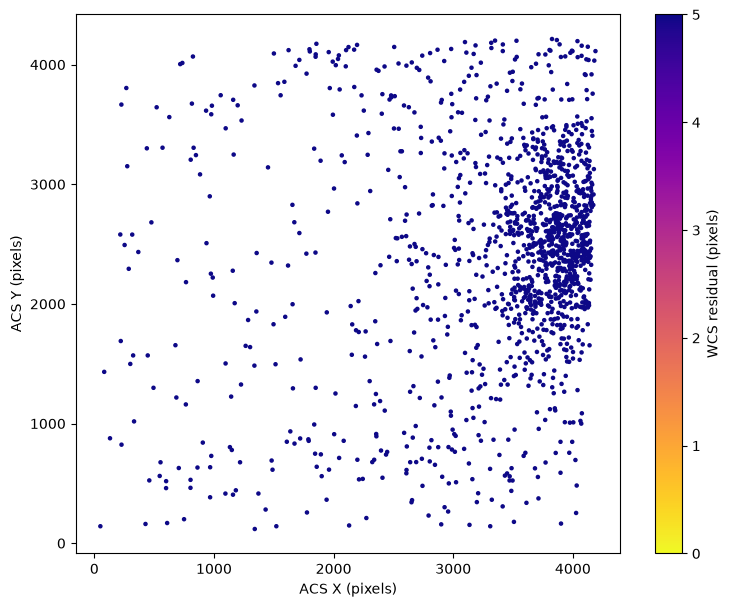

In [18]:
# Assumes cat_2 is the complete catalog for pointing 2-0
# and wcs_2 is the WCS of its original ACS SCI image.

cat_2 = acs_catalogue.loc[(acs_catalogue["pointing"]=="2-0")].copy()
with fits.open(ACS_IMAGES["2-0"], memmap=True) as hdul:
    wcs_2 = WCS(hdul[SCI_EXT].header, hdul).celestial


ACS_IMAGES = {
    "2-0": REGIONS_DIR / "2-0/jc1g01010_drc.fits",
    "3-0": REGIONS_DIR / "3-0/jc1g02010_drc.fits",
}

x_sky, y_sky = wcs_2.world_to_pixel_values(
    cat_2["x_wcs"].to_numpy(),
    cat_2["y_wcs"].to_numpy()
)

cat_2 = cat_2.copy()

cat_2["dx_wcs"] = x_sky - cat_2["x"]
cat_2["dy_wcs"] = y_sky - cat_2["y"]
cat_2["dr_wcs"] = np.hypot(
    cat_2["dx_wcs"], cat_2["dy_wcs"]
)

fig, ax = plt.subplots(figsize=(9, 7))

sc = ax.scatter(
    cat_2["x"],
    cat_2["y"],
    c=cat_2["dr_wcs"],
    s=5,
    cmap="plasma_r",
    vmin=0,
    vmax=5
)

ax.set_aspect("equal")
ax.set_xlabel("ACS X (pixels)")
ax.set_ylabel("ACS Y (pixels)")
fig.colorbar(sc, ax=ax, label="WCS residual (pixels)")
plt.show()

In [19]:
print(cat_2["dr_wcs"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

for threshold in [1, 2, 5, 10, 20, 50]:
    n = (cat_2["dr_wcs"] > threshold).sum()
    print(f"> {threshold:2d} px: {n:5d} "
          f"({100*n/len(cat_2):5.1f}%)")


count    1422.000000
mean       10.265609
std         1.149839
min         7.647168
1%          9.893615
5%          9.981623
25%        10.104507
50%        10.198423
75%        10.307945
95%        10.425660
99%        10.488513
max        38.008810
Name: dr_wcs, dtype: float64
>  1 px:  1422 (100.0%)
>  2 px:  1422 (100.0%)
>  5 px:  1422 (100.0%)
> 10 px:  1329 ( 93.5%)
> 20 px:     4 (  0.3%)
> 50 px:     0 (  0.0%)


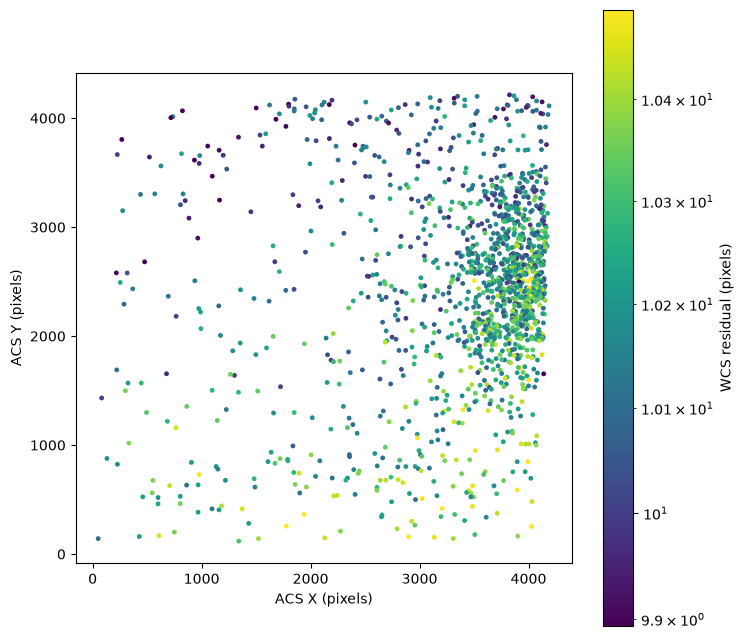

In [20]:
from matplotlib.colors import LogNorm

residual = cat_2["dr_wcs"].to_numpy()

valid = np.isfinite(residual) & (residual > 0)

fig, ax = plt.subplots(figsize=(8, 8))

sc = ax.scatter(
    cat_2.loc[valid, "x"],
    cat_2.loc[valid, "y"],
    c=residual[valid],
    s=6,
    cmap="viridis",
    norm=LogNorm(
        vmin=max(np.nanpercentile(residual[valid], 1), 1e-4),
        vmax=np.nanpercentile(residual[valid], 99)
    )
)

ax.set_aspect("equal")
ax.set_xlabel("ACS X (pixels)")
ax.set_ylabel("ACS Y (pixels)")

fig.colorbar(sc, ax=ax, label="WCS residual (pixels)")
plt.show()


In [21]:
dx0 = cat_2["dx_wcs"].median()
dy0 = cat_2["dy_wcs"].median()

cat_2["dx_resid"] = cat_2["dx_wcs"] - dx0
cat_2["dy_resid"] = cat_2["dy_wcs"] - dy0

cat_2["dr_resid"] = np.hypot(
    cat_2["dx_resid"],
    cat_2["dy_resid"]
)

print(f"Median offset: dx={dx0:+.3f}, dy={dy0:+.3f} pixels")

print(
    cat_2["dr_resid"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)


Median offset: dx=+4.308, dy=-9.244 pixels
count    1422.000000
mean        0.296387
std         1.613239
min         0.002957
50%         0.180732
90%         0.326294
95%         0.370271
99%         0.488445
max        28.278063
Name: dr_resid, dtype: float64


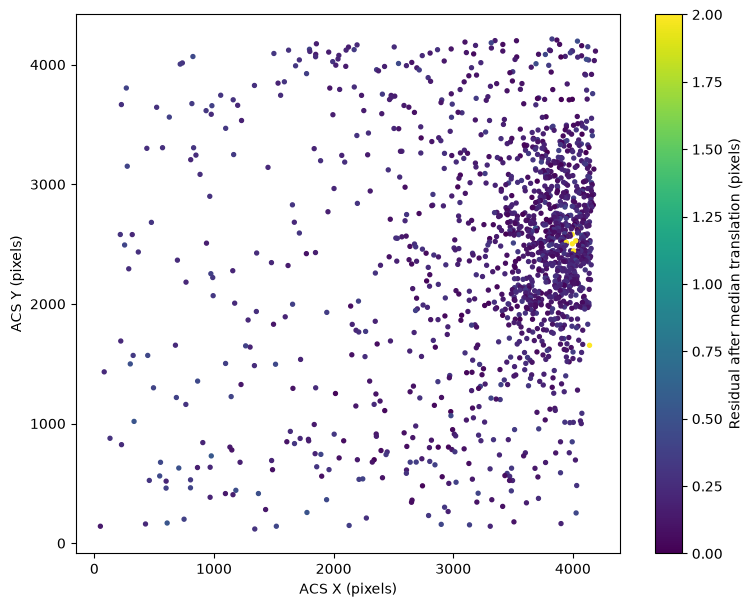

In [22]:
fig, ax = plt.subplots(figsize=(9, 7))

sc = ax.scatter(
    cat_2["x"],
    cat_2["y"],
    c=cat_2["dr_resid"],
    s=8,
    cmap="viridis",
    vmin=0,
    vmax=2
)

fig.colorbar(
    sc, ax=ax,
    label="Residual after median translation (pixels)"
)

ax.set_aspect("equal")
ax.set_xlabel("ACS X (pixels)")
ax.set_ylabel("ACS Y (pixels)")
plt.show()

In [23]:
print(f"Median translation: ({dx0:+.4f}, {dy0:+.4f}) px")

print(
    cat_2["dr_resid"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

for threshold in [0.25, 0.5, 1, 2, 5, 10]:
    n = (cat_2["dr_resid"] > threshold).sum()
    print(f"> {threshold:5.2f} px: {n:4d}")


Median translation: (+4.3076, -9.2440) px
count    1422.000000
mean        0.296387
std         1.613239
min         0.002957
50%         0.180732
90%         0.326294
95%         0.370271
99%         0.488445
max        28.278063
Name: dr_resid, dtype: float64
>  0.25 px:  394
>  0.50 px:   13
>  1.00 px:    8
>  2.00 px:    8
>  5.00 px:    7
> 10.00 px:    6


In [24]:
display(
    cat_2.nlargest(15, "dr_resid")[
        ["x", "y", "dx_wcs", "dy_wcs", "dr_resid"]
    ]
)


,x,y,dx_wcs,dy_wcs,dr_resid
22196,4023.608,2526.765,24.396780,-29.145613,28.278063
22169,3955.258,2564.650,-12.726211,12.388961,27.534274
22132,3994.107,2580.683,-10.042020,11.580146,25.289467
22263,3995.237,2502.300,-9.836785,-29.858844,25.000702
22270,3944.140,2514.001,-16.925532,-20.475885,24.020847
22307,4005.345,2443.044,0.527273,-26.692824,17.853627
22084,4036.683,2621.664,9.697987,-7.642442,5.623278
22830,4139.193,1653.880,4.451478,-6.218000,3.029428
23324,977.424,729.512,3.997004,-9.689086,0.542738
23348,608.576,168.534,3.986092,-9.661177,0.526687


In [25]:
# Fit established from the non-outlier ACS objects
dx0 = cat_2["dx_wcs"].median()
dy0 = cat_2["dy_wcs"].median()

# Convert stored ACS pixels into the sky-coordinate
# reference frame implied by the catalog's normal population.
#
# IMPORTANT: dx0,dy0 are world_to_pixel(catalog RA/Dec)
# minus stored catalog XY.

ra_pred, dec_pred = wcs_2.pixel_to_world_values(
    cat_2["x"].to_numpy() + dx0,
    cat_2["y"].to_numpy() + dy0,
)

cat_2["ra_from_xy"] = ra_pred
cat_2["dec_from_xy"] = dec_pred



# Refine Astrometry

Now, implement a routine that:
1. Estimates the bulk ACS coordinate transformation using robust statistics.
2. Identifies anomalous records without modifying their original coordinates.
3. Validates the resulting registration against reliable JWST detections.
4. Exports the corrected coordinates, quality flags, and transformation metadata.
Once that's working, generalize it to the remaining ACS pointings.

One important safeguard: preserve the upstream gc, ucd, and cand classifications exactly as supplied, including objects without reliable JWST matches.

## Perform robust iterative fitting


In [26]:
from src.acs_astrometry import (
    Settings,
    reconcile_acs_catalog,
    save_reconciliation,
)

acs_parent = data.copy()

cfg = Settings(
    ra_col="x_wcs",
    dec_col="y_wcs",
    max_internal_residual_pix=1.0,
)

images = {
    "2-0":  REGIONS_DIR / "2-0/jc1g01010_drc.fits",
    "3-0":  REGIONS_DIR / "3-0/jc1g02010_drc.fits",
    "OS21": REGIONS_DIR / "OS21/h_v63_F814W_ivm_drz_cl_ver2.fits",
    "OS13": REGIONS_DIR / "OS13/h_v90_F814W_ivm_drz_cl_ver2.fits",
    "OS36": REGIONS_DIR / "OS36/h_v78_F814W_ivm_drz_cl_ver2.fits",
    "OS3":  REGIONS_DIR / "OS3/h_v45_F814W_ivm_drz_cl_ver2.fits",
    "OS17": REGIONS_DIR / "OS17/h_v59_F814W_ivm_drz_cl_ver2.fits",
    "OS4":  REGIONS_DIR / "OS4/h_v46_F814W_ivm_drz_cl_ver2.fits",
    "7-7":  REGIONS_DIR / "7-7/h_v75_F814W_ivm_drz_cl_ver2.fits",
    "2-7":  REGIONS_DIR / "2-7/h_v14_F814W_ivm_drz_cl_ver2.fits",
    "4-6":  REGIONS_DIR / "4-6/jc1g06010_drc.fits",
    "3-6":  REGIONS_DIR / "3-6/jc1g05010_drc.fits",
    "2-6":  REGIONS_DIR / "2-6/h_v13_F814W_ivm_drz_cl_ver2.fits",
    "5-5":  REGIONS_DIR / "5-5/h_v33_F814W_ivm_drz_cl_ver2.fits",
    "4-5":  REGIONS_DIR / "4-5/jc1g04010_drc.fits",
    "3-5":  REGIONS_DIR / "3-5/h_v19_F814W_ivm_drz_cl_ver2.fits",
    "2-5":  REGIONS_DIR / "2-5/h_v12_F814W_ivm_drz_cl_ver2.fits",
    "4-4":  REGIONS_DIR / "4-4/h_v25_F814W_ivm_drz_cl_ver2.fits",
    "3-4":  REGIONS_DIR / "3-4/h_v18_F814W_ivm_drz_cl_ver2.fits",
    "2-4":  REGIONS_DIR / "2-4/jc1g03010_drc.fits",
    "3-3":  REGIONS_DIR / "3-3/jb2i02020_drz.fits",
    "4-3":  REGIONS_DIR / "4-3/h_v24_F814W_ivm_drz_cl_ver2.fits",
    "2-3":  REGIONS_DIR / "2-3/h_v10_F814W_ivm_drz_cl_ver2.fits",
    "1-3":  REGIONS_DIR / "1-3/h_v03_F814W_ivm_drz_cl_ver2.fits",
    "4-2":  REGIONS_DIR / "4-2/h_v23_F814W_ivm_drz_cl_ver2.fits",
    "3-2":  REGIONS_DIR / "3-2/h_v16_F814W_ivm_drz_cl_ver2.fits",
    "2-2":  REGIONS_DIR / "2-2/h_v09_F814W_ivm_drz_cl_ver2.fits",
    "1-2":  REGIONS_DIR / "1-2/h_v02_F814W_ivm_drz_cl_ver2.fits",
    "4-1":  REGIONS_DIR / "4-1/h_v22_F814W_ivm_drz_cl_ver2.fits",
    "3-1":  REGIONS_DIR / "3-1/h_v15_F814W_ivm_drz_cl_ver2.fits",
    "1-1":  REGIONS_DIR / "1-1/h_v01_F814W_ivm_drz_cl_ver2.fits",
}

checked, summary = reconcile_acs_catalog(
    acs_parent.loc[(acs_parent["pointing"]=="2-0") | (acs_parent["pointing"]=="3-0")],
    images,
    cfg,
)

display(summary)
display(checked[checked.astrom_status == "outlier"])

,pointing,fits_file,sci_ext,n_total,n_fit,n_consistent,n_outlier,dx_bulk_pix,dy_bulk_pix,median_residual_pix,p95_residual_pix,jwst_status,jwst_dx_arcsec,jwst_dy_arcsec,jwst_scatter_arcsec,jwst_n_anchors
0,3-0,/Users/richard/PycharmProjects/Coma_Intraclust...,SCI,625,596,624,1,6.109273,-2.337561,0.18643,0.419383,not_checked,NaN,NaN,NaN,0
1,2-0,/Users/richard/PycharmProjects/Coma_Intraclust...,SCI,1422,1400,1414,8,4.308504,-9.243234,0.17993,0.363038,not_checked,NaN,NaN,NaN,0


,x_wcs,y_wcs,flux_814,flux_475,mag_814,mag_475,color,pointing,x,y,...,gc_type_f,pointing_f,Unnamed: 15,astrom_dx_pix,astrom_dy_pix,astrom_resid_pix,ra_reg,dec_reg,astrom_status,astrom_ref
21834,195.22113,28.005536,7.405008,3.149443,23.131781,24.708936,1.577155,3-0,224.417,3367.734,...,gc,3-0,NaN,2.195601,-1.146846,4.090798,NaN,NaN,outlier,acs_catalog_original
22084,195.22531,28.007547,18.592990,5.791457,22.132221,24.047551,1.915329,2-0,4036.683,2621.664,...,ucd,2-0,NaN,9.697987,-7.642442,5.622194,NaN,NaN,outlier,acs_catalog_original
22132,195.22606,28.008181,41.670990,5.467535,21.256010,24.110041,2.854031,2-0,3994.107,2580.683,...,gc,2-0,NaN,-10.042020,11.580146,25.289339,NaN,NaN,outlier,acs_catalog_original
22169,195.22657,28.008599,37.741620,13.306120,21.363543,23.144392,1.780848,2-0,3955.258,2564.650,...,ucd,2-0,NaN,-12.726211,12.388961,27.534222,NaN,NaN,outlier,acs_catalog_original
22196,195.22693,28.006793,88.240770,24.439870,20.441421,22.484273,2.042852,2-0,4023.608,2526.765,...,ucd,2-0,NaN,24.396780,-29.145613,28.277969,NaN,NaN,outlier,acs_catalog_original
22263,195.22773,28.007409,109.254700,15.477880,20.209494,22.980241,2.770747,2-0,3995.237,2502.300,...,gc,2-0,NaN,-9.836785,-29.858844,25.001851,NaN,NaN,outlier,acs_catalog_original
22270,195.22785,28.008262,23.059040,4.691658,21.898492,24.276204,2.377713,2-0,3944.140,2514.001,...,gc,2-0,NaN,-16.925532,-20.475885,24.022005,NaN,NaN,outlier,acs_catalog_original
22307,195.22837,28.006802,13.614340,1.724998,22.470603,25.362549,2.891946,2-0,4005.345,2443.044,...,gc,2-0,NaN,0.527273,-26.692824,17.854576,NaN,NaN,outlier,acs_catalog_original
22830,195.23816,28.000250,1.353786,0.535349,24.976720,26.632928,1.656209,2-0,4139.193,1653.880,...,gc,2-0,NaN,4.451478,-6.218000,3.028611,NaN,NaN,outlier,acs_catalog_original


Do one final sanity check on the `accepted` objects, before moving onto include the JWST comparison.

In [27]:
# Assuming the output DataFrame is named checked

for pointing in ("2-0", "3-0"):
    sub = checked[checked["pointing"] == pointing]

    print(f"\nPointing {pointing}")
    print(sub["astrom_status"].value_counts(dropna=False))

    print(
        sub.groupby("astrom_status")[
            ["ra_reg", "dec_reg"]
        ].apply(
            lambda x: x.notna().all(axis=1).sum()
        )
    )


Pointing 2-0
astrom_status
consistent    1414
outlier          8
Name: count, dtype: int64
astrom_status
consistent    1414
outlier          0
dtype: int64

Pointing 3-0
astrom_status
consistent    624
outlier         1
Name: count, dtype: int64
astrom_status
consistent    624
outlier         0
dtype: int64


## Now inspect the JWST detections



In [28]:
JWST_DET_PATH = HOME_DIR / Path("jwst_coma_pipeline/outputs/03_detection_PGC44832_F150W_v01")


jwst = pd.read_csv(
    JWST_DET_PATH / "pgc44832_F150W_SEP_detections_v01.csv"
)

print(f"Detections: {len(jwst):,}")
print(jwst.columns.tolist())
display(jwst.head())


Detections: 4,740
['source_id', 'thresh', 'npix', 'tnpix', 'xmin', 'xmax', 'ymin', 'ymax', 'x0', 'y0', 'x2', 'y2', 'xy', 'errx2', 'erry2', 'errxy', 'a', 'b', 'theta', 'cxx', 'cyy', 'cxy', 'cflux', 'flux', 'cpeak', 'peak', 'xcpeak', 'ycpeak', 'xpeak', 'ypeak', 'flag', 'x_fits_1based', 'y_fits_1based', 'radius_galaxy_px', 'ellipticity', 'fwhm_moment_approx_px', 'local_rms', 'local_back', 'peak_over_local_rms', 'ra_deg', 'dec_deg']


,source_id,thresh,npix,tnpix,xmin,xmax,ymin,ymax,x0,y0,...,x_fits_1based,y_fits_1based,radius_galaxy_px,ellipticity,fwhm_moment_approx_px,local_rms,local_back,peak_over_local_rms,ra_deg,dec_deg
0,1,0.110323,9,0,1704,1710,0,1,1706.408904,0.769683,...,1707.408904,1.769683,1801.094198,0.825924,2.022001,0.031522,0.030304,3.398820,195.212398,28.016568
1,2,0.109872,7,0,1744,1747,0,1,1745.600652,0.581787,...,1746.600652,1.581787,1799.686517,0.582386,1.779780,0.031392,0.030931,3.480388,195.212632,28.016838
2,3,0.101103,5,0,3352,3353,0,2,3352.646122,0.823324,...,3353.646122,1.823324,2376.556357,0.389144,1.342818,0.028888,0.041113,3.430502,195.222316,28.027848
3,4,0.101420,9,1,3382,3384,0,4,3383.038065,2.016929,...,3384.038065,3.016929,2395.635658,0.609281,1.905984,0.028977,0.041217,4.150411,195.222508,28.028050
4,5,0.110267,7,0,1722,1724,5,7,1722.989618,6.290670,...,1723.989618,7.290670,1794.799241,0.085772,1.643876,0.031504,0.030521,3.428486,195.212540,28.016653


## Exploratory ACS-JWST matching


In [29]:
import numpy as np
from astropy.coordinates import SkyCoord
import astropy.units as u

# ACS: use only positions that passed internal reconciliation
acs_fit = checked.loc[
    (checked["astrom_status"] == "consistent")
    & checked["ra_reg"].notna()
    & checked["dec_reg"].notna()
].copy()

# JWST: conservative initial selection for registration
jwst_fit = jwst.loc[
    (jwst["flag"] == 0)
    & (jwst["peak_over_local_rms"] >= 5)
    & (jwst["x0"] > 20)
    & (jwst["y0"] > 20)
].copy()

print(f"ACS candidates:  {len(acs_fit):,}")
print(f"JWST candidates: {len(jwst_fit):,}")


ACS candidates:  2,038
JWST candidates: 3,329


## Find reciprocal nearest neighbours

In [30]:
acs_sky = SkyCoord(
    acs_fit["ra_reg"].to_numpy() * u.deg,
    acs_fit["dec_reg"].to_numpy() * u.deg,
)

jwst_sky = SkyCoord(
    jwst_fit["ra_deg"].to_numpy() * u.deg,
    jwst_fit["dec_deg"].to_numpy() * u.deg,
)

# Nearest JWST source for each ACS object
idx_j, sep, _ = acs_sky.match_to_catalog_sky(jwst_sky)

# Nearest ACS object for each JWST source
idx_a, _, _ = jwst_sky.match_to_catalog_sky(acs_sky)

# Reciprocal association, generous exploratory radius
mutual = idx_a[idx_j] == np.arange(len(acs_fit))
keep = mutual & (sep.arcsec < 1.5)

matches = acs_fit.iloc[np.flatnonzero(keep)].copy()

matched_jwst = jwst_fit.iloc[idx_j[keep]].copy()

matches["jwst_source_id"] = matched_jwst["source_id"].to_numpy()
matches["jwst_ra"] = matched_jwst["ra_deg"].to_numpy()
matches["jwst_dec"] = matched_jwst["dec_deg"].to_numpy()
matches["sep_arcsec"] = sep.arcsec[keep]

print(f"Reciprocal matches: {len(matches):,}")

display(
    matches["sep_arcsec"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)


Reciprocal matches: 1,131


count    1131.000000
mean        0.409593
std         0.127006
min         0.027887
50%         0.442742
90%         0.463097
95%         0.470174
99%         0.971306
max         1.486866
Name: sep_arcsec, dtype: float64

## Inspect the offset distribution

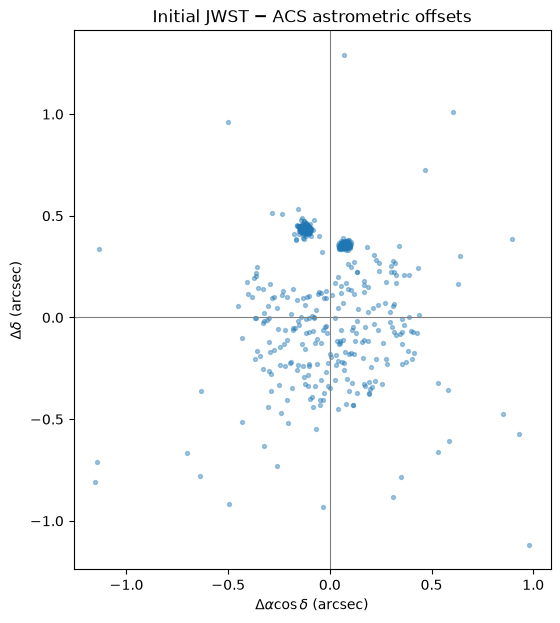

In [31]:
# JWST minus ACS tangent-plane offsets, in arcseconds
matches["dra_arcsec"] = (
    (matches["jwst_ra"] - matches["ra_reg"])
    * np.cos(np.deg2rad(matches["dec_reg"]))
    * 3600
)

matches["ddec_arcsec"] = (
    matches["jwst_dec"] - matches["dec_reg"]
) * 3600

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    matches["dra_arcsec"],
    matches["ddec_arcsec"],
    s=8,
    alpha=0.4,
)

ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)

ax.set(
    xlabel=r"$\Delta\alpha\cos\delta$ (arcsec)",
    ylabel=r"$\Delta\delta$ (arcsec)",
    title="Initial JWST − ACS astrometric offsets",
)
ax.set_aspect("equal")
plt.show()


## Inspect the offsets by pointing

In [32]:
for pointing, group in matches.groupby("pointing"):
    dra0 = group["dra_arcsec"].median()
    ddec0 = group["ddec_arcsec"].median()

    dr = np.hypot(
        group["dra_arcsec"] - dra0,
        group["ddec_arcsec"] - ddec0,
    )

    print(f"\nPointing {pointing}")
    print(f"Matches: {len(group):,}")
    print(f"Median ΔRA cos Dec: {dra0:+.5f} arcsec")
    print(f"Median ΔDec:       {ddec0:+.5f} arcsec")
    print(f"Median offset-subtracted residual: {np.median(dr):.5f} arcsec")
    print(f"95th percentile residual:         {np.percentile(dr, 95):.5f} arcsec")



Pointing 2-0
Matches: 823
Median ΔRA cos Dec: -0.11945 arcsec
Median ΔDec:       +0.43195 arcsec
Median offset-subtracted residual: 0.01693 arcsec
95th percentile residual:         0.82113 arcsec

Pointing 3-0
Matches: 308
Median ΔRA cos Dec: +0.07353 arcsec
Median ΔDec:       +0.35433 arcsec
Median offset-subtracted residual: 0.01270 arcsec
95th percentile residual:         0.56573 arcsec


We have two very distinct, tightly concentrated astrometric-offset populations, one for each ACS pointing. And importantly, their centers are almost identical to the offsets we measured during the original investigation.

That gives us a reassuring independent reproduction of the earlier analysis.

**What we've established**
   
| Measurement | Pointing 2-0 | Pointing 3-0 |
| --- | --- | --- |
| Reciprocal matches | 823 | 308 |
| Median ΔRA cos Dec | −0.11945″ | +0.07353″ |
| Median ΔDec | +0.43195″ | +0.35433″ |
| Median residual after translation | 0.01693″ | 0.01270″ |
| 95th-percentile residual | 0.82113″ | 0.56573″ |

The median offset-subtracted residuals are particularly encouraging: approximately 17 mas and 13 mas, respectively.

However, the 95th-percentile residuals tell us that the sample still contains substantial mismatches. We shouldn't interpret all 1,131 reciprocal associations as reliable registrations.
The plot makes this especially clear
There are two compact concentrations:
- 2-0: approximately \((-0.12'', +0.43'')\)
- 3-0: approximately \((+0.074'', +0.354'')\)
The remaining points form a much broader distribution around the origin, entirely consistent with chance associations, blends, and incorrect reciprocal matches.

The two compact concentrations are our likely true-match populations. We should isolate them before fitting the final correction.

## Initial simple robust inlier selection

Start with a conservative 0.08″ radius around each pointing's median offset.

**Note** - This is a registration-anchor selection, not a final science-matching tolerance.

In [33]:
import numpy as np

matches = matches.copy()

matches["registration_resid_arcsec"] = np.nan
matches["registration_anchor"] = False

for pointing, idx in matches.groupby("pointing").groups.items():
    group = matches.loc[idx]

    dra0 = group["dra_arcsec"].median()
    ddec0 = group["ddec_arcsec"].median()

    dr = np.hypot(
        group["dra_arcsec"] - dra0,
        group["ddec_arcsec"] - ddec0,
    )

    matches.loc[idx, "registration_resid_arcsec"] = dr
    matches.loc[idx, "registration_anchor"] = dr < 0.08

print(
    matches.groupby("pointing")["registration_anchor"]
    .agg(["sum", "count"])
)


          sum  count
pointing            
2-0       598    823
3-0       272    308


In [34]:
registration = []

for pointing, group in matches.groupby("pointing"):
    anchors = group[group["registration_anchor"]]

    dra = anchors["dra_arcsec"].median()
    ddec = anchors["ddec_arcsec"].median()

    residual = np.hypot(
        anchors["dra_arcsec"] - dra,
        anchors["ddec_arcsec"] - ddec,
    )

    registration.append({
        "pointing": pointing,
        "n_anchors": len(anchors),
        "dra_arcsec": dra,
        "ddec_arcsec": ddec,
        "median_resid_arcsec": np.median(residual),
        "p95_resid_arcsec": np.percentile(residual, 95),
    })

registration = pd.DataFrame(registration)

display(registration)


,pointing,n_anchors,dra_arcsec,ddec_arcsec,median_resid_arcsec,p95_resid_arcsec
0,2-0,598,-0.122347,0.435440,0.012682,0.028828
1,3-0,272,0.073846,0.355353,0.010987,0.027428


In [35]:
acs_registered = checked.copy()

for _, row in registration.iterrows():
    mask = (
        (acs_registered["pointing"] == row["pointing"])
        & (acs_registered["astrom_status"] == "consistent")
    )

    dec = acs_registered.loc[mask, "dec_reg"].to_numpy()

    acs_registered.loc[mask, "ra_jwst_frame"] = (
        acs_registered.loc[mask, "ra_reg"].to_numpy()
        + row["dra_arcsec"] / (3600 * np.cos(np.deg2rad(dec)))
    )

    acs_registered.loc[mask, "dec_jwst_frame"] = (
        dec + row["ddec_arcsec"] / 3600
    )


In [36]:
acs_registered = checked.copy()

acs_registered["ra_jwst_frame"] = np.nan
acs_registered["dec_jwst_frame"] = np.nan

for _, solution in registration.iterrows():
    mask = (
        acs_registered["pointing"].eq(solution["pointing"])
        & acs_registered["astrom_status"].eq("consistent")
    )

    dec = acs_registered.loc[mask, "dec_reg"].to_numpy()

    acs_registered.loc[mask, "ra_jwst_frame"] = (
        acs_registered.loc[mask, "ra_reg"].to_numpy()
        + solution["dra_arcsec"]
        / (3600 * np.cos(np.deg2rad(dec)))
    )

    acs_registered.loc[mask, "dec_jwst_frame"] = (
        dec + solution["ddec_arcsec"] / 3600
    )


In [37]:
print(
    acs_registered.groupby(["pointing", "astrom_status"])[
        "ra_jwst_frame"
    ].agg(["count", "size"])
)


                        count  size
pointing astrom_status             
2-0      consistent      1414  1414
         outlier            0     8
3-0      consistent       624   624
         outlier            0     1


All 2,038 consistent ACS objects now have JWST-frame coordinates, and the nine flagged outliers remain untouched.


## Final registration check
Now rerun reciprocal nearest-neighbor matching using ra_jwst_frame and dec_jwst_frame, but with a tighter 0.10″ search radius.

In [38]:
acs_fit = acs_registered.loc[
    acs_registered["astrom_status"].eq("consistent")
    & acs_registered["ra_jwst_frame"].notna()
    & acs_registered["dec_jwst_frame"].notna()
].copy()

acs_sky = SkyCoord(
    ra=acs_fit["ra_jwst_frame"].to_numpy() * u.deg,
    dec=acs_fit["dec_jwst_frame"].to_numpy() * u.deg,
)

# Reuse the quality-filtered JWST detections
jwst_sky = SkyCoord(
    ra=jwst_fit["ra_deg"].to_numpy() * u.deg,
    dec=jwst_fit["dec_deg"].to_numpy() * u.deg,
)

idx_j, sep, _ = acs_sky.match_to_catalog_sky(jwst_sky)
idx_a, _, _ = jwst_sky.match_to_catalog_sky(acs_sky)

mutual = idx_a[idx_j] == np.arange(len(acs_fit))
keep = mutual & (sep.arcsec < 0.10)

matched = acs_fit.iloc[np.flatnonzero(keep)].copy()
matched["jwst_source_id"] = (
    jwst_fit.iloc[idx_j[keep]]["source_id"].to_numpy()
)
matched["sep_arcsec"] = sep.arcsec[keep]

print("Matched objects by pointing:")
print(matched.groupby("pointing").size())

print("\nSeparation statistics:")
print(
    matched.groupby("pointing")["sep_arcsec"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)


Matched objects by pointing:
pointing
2-0    839
3-0    308
dtype: int64

Separation statistics:
          count      mean       std       min       50%       90%       95%  \
pointing                                                                      
2-0       839.0  0.014197  0.009685  0.000514  0.012507  0.024053  0.029569   
3-0       308.0  0.012479  0.007724  0.000182  0.011295  0.022805  0.027504   

               99%       max  
pointing                      
2-0       0.052336  0.083619  
3-0       0.033972  0.040823  


These results are consistent between the two ACS pointings.

**Final ACS–JWST matching results**
Reciprocal matches: 1,147

Median separation: ~12 mas

Matching radius: 0.10″


Metric | ACS 2-0 | ACS 3-0
---  | --- | ---
Matched sources | 839 | 308
Median separation | 0.01251″ | 0.01130″
95th percentile | 0.02957″ | 0.02750″
99th percentile | 0.05234″ | 0.03397″
Maximum | 0.08362″ | 0.04082″

The result is that 95% of the matches lie within approximately 0.03″ in both pointings — less than one NIRCam short-wavelength pixel.

So we've recovered 1,147 reciprocal associations, compared with 1,131 in the original exploratory search.

The normal caveat stands though: these are **registration-adjusted nearest-neighbor separations**, not yet independently validated **photometric associations**. Some sources helped determine the translations, and crowded-field coincidences remain possible.

Flag matches with separations above 0.05″ for later inspection.


In [39]:
matched["match_quality"] = np.where(
    matched["sep_arcsec"] <= 0.05,
    "high_confidence",
    "review",
)

print(
    matched.groupby(["pointing", "match_quality"])
    .size()
)


pointing  match_quality  
2-0       high_confidence    829
          review              10
3-0       high_confidence    308
dtype: int64


In [40]:

output_dir = DATA_DIR / Path("processed")
output_dir.mkdir(parents=True, exist_ok=True)

acs_registered.to_csv(
    output_dir / "acs_registered_2-0_3-0.csv",
    index=False,
)

registration.to_csv(
    output_dir / "acs_jwst_registration_2-0_3-0.csv",
    index=False,
)

matched.to_csv(
    output_dir / "acs_jwst_matches_2-0_3-0.csv",
    index=True,
    index_label="acs_catalog_index",
)

## Check differences for original and new helper

In [41]:
import pandas as pd
import numpy as np

original = pd.read_csv(HOME_DIR / "Coma_Intracluster_GC" / "data/coma_astrometry/processed/acs_registered_2-0_3-0.csv")
check = pd.read_csv(DATA_DIR / "processed/acs_registered_2-0_3-0.csv")

logger.debug("acs_registered_2-0_3-0 comparison")
print("Shapes:", original.shape, check.shape)
print("Columns identical:", original.columns.equals(check.columns))
print("Column differences:", set(original.columns) ^ set(check.columns))

[DEBUG] 19:57:35.515 acs_registered_2-0_3-0 comparison


Shapes: (2047, 25) (2047, 25)
Columns identical: True
Column differences: set()


In [42]:
pd.testing.assert_frame_equal(
    original,
    check,
    check_exact=False,
    rtol=1e-10,
    atol=1e-12,
)
print("Exact equality:", original.equals(check))


Exact equality: True


In [43]:
import pandas as pd
import numpy as np

original = pd.read_csv(HOME_DIR / "Coma_Intracluster_GC" / "data/coma_astrometry/processed/acs_jwst_registration_2-0_3-0.csv")
check = pd.read_csv(DATA_DIR / "processed/acs_jwst_registration_2-0_3-0.csv")

logger.debug("acs_jwst_registration_2-0_3-0 comparison")
print("Shapes:", original.shape, check.shape)
print("Columns identical:", original.columns.equals(check.columns))
print("Column differences:", set(original.columns) ^ set(check.columns))

[DEBUG] 19:57:39.308 acs_jwst_registration_2-0_3-0 comparison


Shapes: (2, 6) (2, 6)
Columns identical: True
Column differences: set()


In [44]:
pd.testing.assert_frame_equal(
    original,
    check,
    check_exact=False,
    rtol=1e-10,
    atol=1e-12,
)
print("Exact equality:", original.equals(check))


Exact equality: True


In [45]:
import pandas as pd
import numpy as np

original = pd.read_csv(HOME_DIR / "Coma_Intracluster_GC" / "data/coma_astrometry/processed/acs_jwst_matches_2-0_3-0.csv")
check = pd.read_csv(DATA_DIR / "processed/acs_jwst_matches_2-0_3-0.csv")

logger.debug("acs_jwst_matches_2-0_3-0 comparison")
print("Shapes:", original.shape, check.shape)
print("Columns identical:", original.columns.equals(check.columns))
print("Column differences:", set(original.columns) ^ set(check.columns))

[DEBUG] 19:57:42.606 acs_jwst_matches_2-0_3-0 comparison


Shapes: (1147, 29) (1147, 29)
Columns identical: True
Column differences: set()


In [46]:
pd.testing.assert_frame_equal(
    original,
    check,
    check_exact=False,
    rtol=1e-10,
    atol=1e-12,
)
print("Exact equality:", original.equals(check))


Exact equality: True
